## 1. Setup & Import

In [1]:
import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.base import clone
from sklearn.model_selection import train_test_split

from utils import (
    fix_european, evaluate, diagnose_fit,
    run_nocv, run_cv,
    run_nocv_tuned, run_cv_tuned, tune_model,
    show_fold_table,
    make_feature_sets_split, make_feature_sets_cv,
    plot_mcc_heatmap, plot_mcc_bar, plot_gap_analysis,
    MODEL_NAMES, METRICS, TARGET, DROP,
    INNER_CV_FOLDS, RANDOM_STATE,
    PARAM_GRID_SVM, PARAM_GRID_RF, PARAM_GRID_XGB
)

print('Import selesai.')
print(f'MODEL_NAMES    : {MODEL_NAMES}')
print(f'INNER_CV_FOLDS : {INNER_CV_FOLDS}  (inner CV untuk Grid Search)')
print()
print('Ringkasan Grid Search Parameter:')
print(f'  SVM  : 30 kombinasi  × {INNER_CV_FOLDS} inner fold = 90 inner fits')
print(f'  RF   : 36 kombinasi  × {INNER_CV_FOLDS} inner fold = 108 inner fits')
print(f'  XGB  : 108 kombinasi × {INNER_CV_FOLDS} inner fold = 324 inner fits')
print()
print('PARAM_GRID_SVM :', PARAM_GRID_SVM)
print('PARAM_GRID_RF  :', PARAM_GRID_RF)
print('PARAM_GRID_XGB :', PARAM_GRID_XGB)

Import selesai.
MODEL_NAMES    : ['SVM', 'Random Forest', 'XGBoost']
INNER_CV_FOLDS : 3  (inner CV untuk Grid Search)

Ringkasan Grid Search Parameter:
  SVM  : 30 kombinasi  × 3 inner fold = 90 inner fits
  RF   : 36 kombinasi  × 3 inner fold = 108 inner fits
  XGB  : 108 kombinasi × 3 inner fold = 324 inner fits

PARAM_GRID_SVM : [{'kernel': ['linear'], 'C': [0.01, 0.1, 1, 10, 100]}, {'kernel': ['rbf'], 'C': [0.01, 0.1, 1, 10, 100], 'gamma': ['scale', 'auto']}, {'kernel': ['poly'], 'C': [0.01, 0.1, 1, 10, 100], 'degree': [2, 3, 4]}]
PARAM_GRID_RF  : {'n_estimators': [100, 200, 300], 'max_depth': [5, 10, None], 'max_features': ['sqrt', 'log2'], 'min_samples_split': [2, 5]}
PARAM_GRID_XGB : {'learning_rate': [0.01, 0.1, 0.3], 'max_depth': [3, 6, 9], 'n_estimators': [100, 200, 300], 'subsample': [0.7, 1.0], 'colsample_bytree': [0.7, 1.0]}


## 2. Load & Preprocessing

In [6]:
df_train = pd.read_csv(
    'D:\Skripsi - DIAD\dataset\DIA_trainingset_RDKit_descriptors.csv',
    sep=','
)

df_test = pd.read_csv(
    'D:\Skripsi - DIAD\dataset\DIA_testset_RDKit_descriptors.csv',
    sep=','
)

print('Train:', df_train.shape, '| Label:', dict(df_train['Label'].value_counts()))
print('Test :', df_test.shape, '| Label:', dict(df_test['Label'].value_counts()))

Train: (477, 198) | Label: {0: np.int64(359), 1: np.int64(118)}
Test : (120, 198) | Label: {0: np.int64(90), 1: np.int64(30)}


In [ ]:
X_train = fix_european(df_train.drop(columns=DROP))
y_train = df_train[TARGET]
X_test  = fix_european(df_test.drop(columns=DROP))
y_test  = df_test[TARGET]

X_full = pd.concat([X_train, X_test], axis=0).reset_index(drop=True)
y_full = pd.concat([y_train, y_test], axis=0).reset_index(drop=True)

Xtr80  = Xtr80.fillna(0).reset_index(drop=True)
Xte80  = Xte80.fillna(0).reset_index(drop=True)
X_full = X_full.fillna(0) 

Xtr80, Xte80, ytr80, yte80 = train_test_split(
    X_full, y_full, test_size=0.20, random_state=42, stratify=y_full)
Xtr70, Xte70, ytr70, yte70 = train_test_split(
    X_full, y_full, test_size=0.30, random_state=42, stratify=y_full)

models = {m: None for m in MODEL_NAMES}

print(f'Full  : {X_full.shape}')
print(f'80:20 → Train: {Xtr80.shape} | Test: {Xte80.shape}')
print(f'70:30 → Train: {Xtr70.shape} | Test: {Xte70.shape}')
print(f'Distribusi y_full: {dict(y_full.value_counts())}')

Full  : (597, 196)
80:20 → Train: (477, 196) | Test: (120, 196)
70:30 → Train: (417, 196) | Test: (180, 196)
Distribusi y_full: {0: np.int64(449), 1: np.int64(148)}


## 3. Hyperparameter Tuning — Grid Search CV

Seluruh fungsi tuning menggunakan `sklearn.model_selection.GridSearchCV` dengan konfigurasi:

| Parameter GridSearchCV | Nilai | Keterangan |
|------------------------|-------|------------|
| `scoring`              | `'matthews_corrcoef'` | Metrik optimasi — konsisten dengan metrik evaluasi utama |
| `cv`                   | `StratifiedKFold(n_splits=3)` | Inner 3-fold CV, stratified agar distribusi kelas terjaga |
| `refit`                | `True` | Model terbaik di-refit pada seluruh X_tr setelah pencarian |
| `n_jobs`               | `-1` | Paralel menggunakan seluruh CPU yang tersedia |

**Alur Nested CV per outer fold:**
1. Outer split → `X_tr_raw`, `X_val_raw`
2. Preprocessing fit **hanya** pada `X_tr_raw` (no leakage)
3. `GridSearchCV` dengan inner 3-fold pada `X_tr` → model terbaik
4. Evaluasi model terbaik pada `X_val`

**Justifikasi pemilihan Grid Search:**
- *Exhaustive & deterministik*: seluruh kombinasi dievaluasi; hasil identik di setiap run (Bergstra & Bengio, 2012)
- *Reproducible*: tidak ada komponen probabilistik (berbeda dengan Optuna TPE sampler)
- *Interpretable*: seluruh hasil grid dapat ditabulasi untuk dokumentasi BAB III
- *Native sklearn*: tidak memerlukan dependensi eksternal tambahan

**Referensi:**
> Bergstra, J. & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13, 281–305.
> Probst, P., Wright, M. N., & Boulesteix, A. L. (2019). Hyperparameters and tuning strategies for random forest. *WIREs Data Mining*, 9(3), e1301.


## 4. Feature Sets

In [9]:
fs_8020    = make_feature_sets_split(
    Xtr80.reset_index(drop=True),
    Xte80.reset_index(drop=True),
    ytr80.reset_index(drop=True))

fs_7030    = make_feature_sets_split(
    Xtr70.reset_index(drop=True),
    Xte70.reset_index(drop=True),
    ytr70.reset_index(drop=True))

fs_cv      = make_feature_sets_cv(X_full)
fs_cv_8020 = make_feature_sets_cv(Xtr80.reset_index(drop=True))
fs_cv_7030 = make_feature_sets_cv(Xtr70.reset_index(drop=True))

print('Feature sets siap.')
print('\nJumlah fitur per metode FS (dihitung dari Xtr80):')
for name, (Xtr_i, _) in fs_8020.items():
    print(f'  {name:<22}: {Xtr_i.shape[1]} fitur')

Feature sets siap.

Jumlah fitur per metode FS (dihitung dari Xtr80):
  Baseline              : 196 fitur
  Variance Threshold    : 169 fitur
  Zero Dominant         : 112 fitur
  Spearman              : 131 fitur
  Mutual Information    : 95 fitur


## 5A. Evaluasi — Strategi Holdout (S1–S2)

In [10]:
print('=== S1: Full Data 80:20 Holdout ===')
rows_s1 = run_nocv_tuned(
    fs_dict = fs_8020,
    y_train = ytr80.reset_index(drop=True),
    y_test  = yte80.reset_index(drop=True),
    label   = 'Full Data 80:20'
)
print('S1 selesai.')

=== S1: Full Data 80:20 Holdout ===
S1 selesai.


In [11]:
print('=== S2: Full Data 70:30 Holdout ===')
rows_s2 = run_nocv_tuned(
    fs_dict = fs_7030,
    y_train = ytr70.reset_index(drop=True),
    y_test  = yte70.reset_index(drop=True),
    label   = 'Full Data 70:30'
)
print('S2 selesai.')

=== S2: Full Data 70:30 Holdout ===
S2 selesai.


## 5B. Evaluasi — Strategi KFold CV (S3–S8)

> **Catatan:** Setiap sel evaluasi CV menampilkan tabel per-fold secara otomatis via `show_fold_table()`.
> Tabel berisi nilai metrik validasi (Accuracy, Precision, Recall, F1-Score, MCC, ROC-AUC) per fold,
> diikuti baris **Mean** dan **Std** dari seluruh fold.


In [12]:
print('=== S3: 5-Fold CV ===')
rows_s3, fold_s3 = run_cv_tuned(
    X          = X_full.reset_index(drop=True),
    fs_dict    = fs_cv,
    y          = y_full.reset_index(drop=True),
    n_splits   = 5,
    label      = '5-Fold CV',
    stratified = False
)
show_fold_table(fold_s3, 'S3: 5-Fold CV')
print('S3 selesai.')

=== S3: 5-Fold CV ===

  TABEL PER-FOLD — S3: 5-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7917,0.7353,0.7486,0.7412,0.4837,0.8565
2,0.8167,0.7439,0.7314,0.7372,0.4751,0.8529
3,0.8067,0.7180,0.7239,0.7209,0.4419,0.7883
4,0.8403,0.8091,0.7775,0.7906,0.5857,0.8665
5,0.7983,0.7353,0.6563,0.6766,0.3836,0.7226
Mean,0.8107,0.7483,0.7275,0.7333,0.4740,0.8174
Std,0.0190,0.0353,0.0448,0.0410,0.0738,0.0613




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8250,0.8429,0.6918,0.7222,0.5128,0.8718
2,0.8417,0.8720,0.6731,0.7091,0.5076,0.8300
3,0.8403,0.8626,0.6485,0.6818,0.4641,0.8586
4,0.8235,0.8690,0.6912,0.7216,0.5312,0.8661
5,0.7983,0.7664,0.6213,0.6394,0.3595,0.8418
Mean,0.8258,0.8426,0.6652,0.6948,0.4750,0.8537
Std,0.0175,0.0441,0.0302,0.0350,0.0691,0.0174




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8083,0.8048,0.6705,0.6957,0.4558,0.8572
2,0.8500,0.8796,0.6910,0.7300,0.5385,0.8346
3,0.8403,0.9152,0.6346,0.6658,0.4728,0.8418
4,0.8067,0.8555,0.6609,0.6849,0.4783,0.8830
5,0.7983,0.7420,0.6446,0.6654,0.3742,0.8360
Mean,0.8207,0.8394,0.6603,0.6884,0.4639,0.8505
Std,0.0229,0.0676,0.0221,0.0266,0.0591,0.0202




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8000,0.7444,0.7344,0.7390,0.4787,0.8281
2,0.8500,0.7930,0.7780,0.7849,0.5707,0.8610
3,0.8319,0.7593,0.7124,0.7305,0.4694,0.8594
4,0.8151,0.7802,0.7320,0.7492,0.5100,0.8612
5,0.8067,0.7442,0.6852,0.7045,0.4254,0.8644
Mean,0.8207,0.7642,0.7284,0.7416,0.4908,0.8548
Std,0.0202,0.0218,0.0340,0.0293,0.0539,0.0150



S3 selesai.


In [13]:
print('=== S4: 10-Fold CV ===')
rows_s4, fold_s4 = run_cv_tuned(
    X          = X_full.reset_index(drop=True),
    fs_dict    = fs_cv,
    y          = y_full.reset_index(drop=True),
    n_splits   = 10,
    label      = '10-Fold CV',
    stratified = False
)
show_fold_table(fold_s4, 'S4: 10-Fold CV')
print('S4 selesai.')

=== S4: 10-Fold CV ===

  TABEL PER-FOLD — S4: 10-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8000,0.7893,0.7582,0.7689,0.5467,0.8144
2,0.7333,0.6354,0.6957,0.6444,0.3256,0.7885
3,0.8833,0.7997,0.8581,0.8232,0.6552,0.8293
4,0.7833,0.7396,0.6888,0.7044,0.4253,0.7839
5,0.8333,0.7422,0.7708,0.7545,0.5123,0.8767
6,0.8167,0.7439,0.7314,0.7372,0.4751,0.8393
7,0.8833,0.8742,0.8297,0.8478,0.7025,0.8550
8,0.8136,0.8395,0.6940,0.7209,0.5132,0.8627
9,0.7627,0.6802,0.6968,0.6871,0.3767,0.8222




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.8980,0.7619,0.7869,0.6457,0.9438
2,0.8333,0.7197,0.6512,0.6732,0.3645,0.8089
3,0.9167,0.9537,0.7727,0.8287,0.7035,0.9777
4,0.8000,0.8909,0.6471,0.6660,0.4795,0.7743
5,0.8667,0.9286,0.6667,0.7115,0.5345,0.8576
6,0.8500,0.8531,0.7034,0.7403,0.5360,0.9068
7,0.8500,0.9135,0.7353,0.7726,0.6238,0.9118
8,0.8136,0.8395,0.6940,0.7209,0.5132,0.8375
9,0.7966,0.7750,0.5960,0.6067,0.3250,0.8238




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7500,0.8611,0.6429,0.6416,0.4543,0.9133
2,0.8333,0.7197,0.6512,0.6732,0.3645,0.7904
3,0.8833,0.8269,0.7523,0.7811,0.5744,0.8571
4,0.8000,0.8909,0.6471,0.6660,0.4795,0.7934
5,0.8500,0.7911,0.6875,0.7186,0.4673,0.8438
6,0.8667,0.9259,0.7143,0.7600,0.6042,0.8602
7,0.8667,0.9216,0.7647,0.8036,0.6681,0.9289
8,0.8136,0.8395,0.6940,0.7209,0.5132,0.8179
9,0.7966,0.7750,0.5960,0.6067,0.3250,0.8143




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8167,0.8056,0.7821,0.7911,0.5871,0.9219
2,0.7833,0.6458,0.6558,0.6504,0.3015,0.7625
3,0.9000,0.8330,0.8330,0.8330,0.6660,0.9462
4,0.8167,0.8413,0.6943,0.7221,0.5150,0.8714
5,0.8667,0.7917,0.7917,0.7917,0.5833,0.8715
6,0.8500,0.7930,0.7780,0.7849,0.5707,0.8432
7,0.8667,0.8592,0.8003,0.8222,0.6569,0.8824
8,0.7797,0.7376,0.6877,0.7028,0.4223,0.8319
9,0.7627,0.6582,0.6230,0.6339,0.2790,0.7667



S4 selesai.


In [14]:
print('=== S5: Full Data 80:20 + 5-Fold CV ===')
rows_s5, fold_s5 = run_cv_tuned(
    X          = Xtr80.reset_index(drop=True),
    fs_dict    = fs_cv_8020,
    y          = ytr80.reset_index(drop=True),
    n_splits   = 5,
    label      = 'Full Data 80:20 + 5-Fold CV',
    stratified = False
)
show_fold_table(fold_s5, 'S5: Full Data 80:20 + 5-Fold CV')
print('S5 selesai.')

=== S5: Full Data 80:20 + 5-Fold CV ===

  TABEL PER-FOLD — S5: Full Data 80:20 + 5-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8646,0.8312,0.7770,0.7984,0.6057,0.8076
2,0.7604,0.6907,0.6955,0.6929,0.3861,0.7166
3,0.7368,0.6382,0.6341,0.6360,0.2723,0.6920
4,0.8105,0.7862,0.7476,0.7617,0.5325,0.8485
5,0.8421,0.7452,0.7749,0.7580,0.5192,0.8514
Mean,0.8029,0.7383,0.7258,0.7294,0.4632,0.7832
Std,0.0538,0.0763,0.0609,0.0646,0.1329,0.0746




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8229,0.8128,0.6602,0.6890,0.4477,0.7796
2,0.8229,0.8075,0.6989,0.7265,0.4946,0.7504
3,0.8316,0.9091,0.6522,0.6833,0.4990,0.7953
4,0.7789,0.8022,0.6573,0.6734,0.4360,0.8986
5,0.8526,0.7601,0.7601,0.7601,0.5202,0.7540
Mean,0.8218,0.8183,0.6857,0.7065,0.4795,0.7956
Std,0.0269,0.0549,0.0455,0.0361,0.0359,0.0605




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8229,0.9056,0.6304,0.6547,0.4600,0.8011
2,0.8021,0.7562,0.6848,0.7054,0.4352,0.7082
3,0.8316,0.9091,0.6522,0.6833,0.4990,0.8007
4,0.7789,0.8022,0.6573,0.6734,0.4360,0.8668
5,0.8316,0.7294,0.6407,0.6649,0.3593,0.8160
Mean,0.8134,0.8205,0.6531,0.6763,0.4379,0.7986
Std,0.0228,0.0835,0.0206,0.0194,0.0510,0.0573




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8438,0.8197,0.7186,0.7489,0.5287,0.8374
2,0.8333,0.7862,0.7707,0.7778,0.5567,0.7307
3,0.8105,0.7521,0.6827,0.7039,0.4292,0.7899
4,0.8105,0.7931,0.7380,0.7557,0.5282,0.8908
5,0.8421,0.7452,0.7749,0.7580,0.5192,0.8232
Mean,0.8280,0.7793,0.7370,0.7489,0.5124,0.8144
Std,0.0165,0.0307,0.0383,0.0273,0.0486,0.0593



S5 selesai.


In [15]:
print('=== S6: Full Data 80:20 + 10-Fold CV ===')
rows_s6, fold_s6 = run_cv_tuned(
    X          = Xtr80.reset_index(drop=True),
    fs_dict    = fs_cv_8020,
    y          = ytr80.reset_index(drop=True),
    n_splits   = 10,
    label      = 'Full Data 80:20 + 10-Fold CV',
    stratified = False
)
show_fold_table(fold_s6, 'S6: Full Data 80:20 + 10-Fold CV')
print('S6 selesai.')

=== S6: Full Data 80:20 + 10-Fold CV ===

  TABEL PER-FOLD — S6: Full Data 80:20 + 10-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.9583,0.9722,0.9286,0.9473,0.8997,0.9223
2,0.8750,0.8084,0.7521,0.7750,0.5577,0.7607
3,0.7708,0.6806,0.6916,0.6855,0.3720,0.7322
4,0.7083,0.6471,0.6471,0.6471,0.2941,0.7458
5,0.8125,0.7718,0.6806,0.7047,0.4430,0.7662
6,0.7083,0.5750,0.5556,0.5579,0.1291,0.6898
7,0.7917,0.7394,0.7604,0.7479,0.4994,0.8659
8,0.8085,0.8349,0.7177,0.7410,0.5401,0.8458
9,0.7872,0.6731,0.6459,0.6564,0.3179,0.7351




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.8211,0.7563,0.7778,0.5737,0.7584
2,0.8750,0.8419,0.7094,0.7491,0.5351,0.8319
3,0.7917,0.7003,0.6413,0.6581,0.3365,0.7592
4,0.7708,0.7837,0.6282,0.6391,0.3814,0.8172
5,0.8542,0.9186,0.7083,0.7498,0.5906,0.7431
6,0.7917,0.8913,0.5833,0.5819,0.3612,0.9398
7,0.7917,0.7953,0.6396,0.6581,0.4060,0.8374
8,0.7872,0.8161,0.6844,0.7033,0.4828,0.8604
9,0.8085,0.7172,0.7324,0.7241,0.4493,0.7189




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8125,0.8953,0.6786,0.7047,0.5314,0.8592
2,0.8333,0.7247,0.6838,0.7000,0.4064,0.8091
3,0.8333,0.8186,0.6683,0.7000,0.4631,0.8084
4,0.7917,0.7750,0.6849,0.7052,0.4510,0.7836
5,0.8333,0.9091,0.6667,0.7000,0.5222,0.6597
6,0.7917,0.8913,0.5833,0.5819,0.3612,0.9097
7,0.7917,0.7596,0.6637,0.6842,0.4123,0.8703
8,0.7872,0.8810,0.6667,0.6824,0.5040,0.8479
9,0.7660,0.6578,0.6689,0.6628,0.3266,0.6892




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8750,0.9250,0.7857,0.8231,0.6969,0.9328
2,0.8542,0.7625,0.7393,0.7498,0.5013,0.8803
3,0.8125,0.7342,0.7187,0.7257,0.4526,0.8206
4,0.8542,0.8275,0.8130,0.8196,0.6403,0.7836
5,0.8333,0.8000,0.7222,0.7474,0.5164,0.7569
6,0.8333,0.9091,0.6667,0.7000,0.5222,0.7870
7,0.8542,0.8342,0.7791,0.7999,0.6109,0.8945
8,0.7447,0.7071,0.6708,0.6810,0.3762,0.8438
9,0.8723,0.8095,0.8095,0.8095,0.6189,0.8378



S6 selesai.


In [16]:
print('=== S7: Full Data 70:30 + 5-Fold CV ===')
rows_s7, fold_s7 = run_cv_tuned(
    X          = Xtr70.reset_index(drop=True),
    fs_dict    = fs_cv_7030,
    y          = ytr70.reset_index(drop=True),
    n_splits   = 5,
    label      = 'Full Data 70:30 + 5-Fold CV',
    stratified = False
)
show_fold_table(fold_s7, 'S7: Full Data 70:30 + 5-Fold CV')
print('S7 selesai.')

=== S7: Full Data 70:30 + 5-Fold CV ===

  TABEL PER-FOLD — S7: Full Data 70:30 + 5-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8095,0.7454,0.7891,0.7605,0.5326,0.7766
2,0.7976,0.7195,0.6953,0.7054,0.4141,0.8242
3,0.8313,0.7629,0.7426,0.7517,0.5051,0.8224
4,0.7831,0.6926,0.7209,0.7036,0.4126,0.7449
5,0.7711,0.7405,0.6974,0.7104,0.4358,0.7800
Mean,0.7985,0.7322,0.7291,0.7263,0.4600,0.7896
Std,0.0234,0.0270,0.0387,0.0275,0.0553,0.0337




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.8520,0.6672,0.7000,0.4852,0.7859
2,0.7976,0.8951,0.5750,0.5718,0.3443,0.7957
3,0.8193,0.9051,0.6053,0.6215,0.4130,0.8273
4,0.8193,0.7363,0.6838,0.7025,0.4167,0.7872
5,0.7229,0.6750,0.6204,0.6275,0.2904,0.6815
Mean,0.7985,0.8127,0.6303,0.6447,0.3899,0.7755
Std,0.0441,0.1021,0.0447,0.0560,0.0747,0.0552




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8452,0.8644,0.6922,0.7291,0.5293,0.8125
2,0.8095,0.9000,0.6000,0.6111,0.4000,0.7531
3,0.8072,0.9000,0.5789,0.5808,0.3554,0.7891
4,0.8554,0.8315,0.7068,0.7422,0.5237,0.7470
5,0.7590,0.7767,0.6363,0.6453,0.3884,0.7490
Mean,0.8153,0.8545,0.6428,0.6617,0.4394,0.7701
Std,0.0380,0.0520,0.0559,0.0714,0.0812,0.0293




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.7776,0.7359,0.7525,0.5118,0.8305
2,0.8095,0.7429,0.6859,0.7050,0.4250,0.8383
3,0.8554,0.8396,0.7212,0.7559,0.5482,0.8232
4,0.8554,0.8116,0.7269,0.7559,0.5318,0.8650
5,0.7831,0.7507,0.7271,0.7362,0.4772,0.8030
Mean,0.8273,0.7845,0.7194,0.7411,0.4988,0.8320
Std,0.0312,0.0409,0.0195,0.0218,0.0490,0.0226



S7 selesai.


In [17]:
print('=== S8: Full Data 70:30 + 10-Fold CV ===')
rows_s8, fold_s8 = run_cv_tuned(
    X          = Xtr70.reset_index(drop=True),
    fs_dict    = fs_cv_7030,
    y          = ytr70.reset_index(drop=True),
    n_splits   = 10,
    label      = 'Full Data 70:30 + 10-Fold CV',
    stratified = False
)
show_fold_table(fold_s8, 'S8: Full Data 70:30 + 10-Fold CV')
print('S8 selesai.')

=== S8: Full Data 70:30 + 10-Fold CV ===



  TABEL PER-FOLD — S8: Full Data 70:30 + 10-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7619,0.6578,0.7429,0.6719,0.3916,0.6735
2,0.8333,0.8219,0.7732,0.7904,0.5931,0.8143
3,0.8095,0.6434,0.6806,0.6571,0.3218,0.8241
4,0.7143,0.6944,0.6071,0.6062,0.2887,0.7296
5,0.8333,0.7537,0.7323,0.7419,0.4855,0.8249
6,0.8333,0.7727,0.7531,0.7619,0.5255,0.7938
7,0.7857,0.7562,0.7175,0.7306,0.4722,0.7294
8,0.8537,0.6849,0.7444,0.7071,0.4252,0.7611
9,0.8537,0.8424,0.8104,0.8233,0.6521,0.8599




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.6750,0.5571,0.5644,0.2000,0.5633
2,0.8095,0.8919,0.6923,0.7172,0.5490,0.8700
3,0.9048,0.8355,0.7361,0.7730,0.5629,0.9630
4,0.6905,0.8415,0.5357,0.4725,0.2209,0.7168
5,0.8333,0.9125,0.6111,0.6339,0.4282,0.8418
6,0.8333,0.9103,0.6500,0.6815,0.4961,0.8562
7,0.7857,0.8816,0.6538,0.6681,0.4846,0.8355
8,0.9512,0.9737,0.8000,0.8615,0.7539,0.8139
9,0.8293,0.9000,0.7308,0.7602,0.6076,0.9093


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8095,0.5897,0.5429,0.5459,0.1240,0.5429
2,0.8333,0.9028,0.7308,0.7619,0.6097,0.8886
3,0.9048,0.8355,0.7361,0.7730,0.5629,0.9167
4,0.6905,0.8415,0.5357,0.4725,0.2209,0.6773
5,0.8333,0.9125,0.6111,0.6339,0.4282,0.7542
6,0.7857,0.8902,0.5500,0.5293,0.2794,0.7250
7,0.7619,0.7429,0.6578,0.6719,0.3916,0.7692
8,0.9512,0.9737,0.8000,0.8615,0.7539,0.8000
9,0.8049,0.8889,0.6923,0.7153,0.5469,0.9093




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8095,0.6324,0.6000,0.6111,0.2302,0.5959
2,0.8810,0.8875,0.8289,0.8503,0.7140,0.8727
3,0.9048,0.8056,0.8056,0.8056,0.6111,0.9491
4,0.6905,0.6795,0.5536,0.5206,0.1961,0.7551
5,0.8333,0.9125,0.6111,0.6339,0.4282,0.7609
6,0.8571,0.8162,0.7688,0.7879,0.5830,0.8344
7,0.7857,0.8056,0.6751,0.6939,0.4626,0.8594
8,0.9024,0.7722,0.7722,0.7722,0.5444,0.8500
9,0.8293,0.8060,0.7926,0.7986,0.5985,0.9203



S8 selesai.


## 5C. Evaluasi — Strategi Stratified KFold CV (S9–S14)

In [18]:
print('=== S9: Stratified 5-Fold CV ===')
rows_s9, fold_s9 = run_cv_tuned(
    X          = X_full.reset_index(drop=True),
    fs_dict    = fs_cv,
    y          = y_full.reset_index(drop=True),
    n_splits   = 5,
    label      = 'Stratified 5-Fold CV',
    stratified = True
)
show_fold_table(fold_s9, 'S9: Stratified 5-Fold CV')
print('S9 selesai.')

=== S9: Stratified 5-Fold CV ===

  TABEL PER-FOLD — S9: Stratified 5-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8000,0.7332,0.7111,0.7205,0.4438,0.7989
2,0.7750,0.6989,0.6944,0.6966,0.3934,0.7969
3,0.8235,0.7608,0.7782,0.7685,0.5387,0.8368
4,0.8067,0.7376,0.7320,0.7347,0.4696,0.7387
5,0.8908,0.8721,0.8275,0.8463,0.6982,0.8813
Mean,0.8192,0.7605,0.7486,0.7533,0.5087,0.8105
Std,0.0437,0.0662,0.0541,0.0581,0.1182,0.0529




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7750,0.7252,0.5833,0.5867,0.2740,0.7807
2,0.8333,0.9091,0.6667,0.7000,0.5222,0.8494
3,0.8319,0.9091,0.6552,0.6868,0.5039,0.9052
4,0.8319,0.8039,0.7019,0.7305,0.4954,0.7663
5,0.8403,0.9120,0.6833,0.7201,0.5497,0.9011
Mean,0.8225,0.8519,0.6581,0.6848,0.4690,0.8405
Std,0.0268,0.0844,0.0454,0.0574,0.1110,0.0652




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7833,0.8070,0.5778,0.5752,0.3091,0.7856
2,0.8167,0.8241,0.6556,0.6825,0.4491,0.7909
3,0.8571,0.9206,0.7069,0.7495,0.5900,0.8782
4,0.8067,0.7667,0.6502,0.6736,0.4003,0.7433
5,0.8067,0.8973,0.6167,0.6320,0.4306,0.8831
Mean,0.8141,0.8431,0.6414,0.6626,0.4358,0.8162
Std,0.0270,0.0641,0.0480,0.0645,0.1016,0.0617




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7833,0.7100,0.6556,0.6716,0.3615,0.7811
2,0.8250,0.7757,0.7278,0.7457,0.5012,0.8402
3,0.8908,0.8803,0.8109,0.8378,0.6877,0.9073
4,0.8067,0.7378,0.7203,0.7281,0.4578,0.7567
5,0.8739,0.8673,0.7831,0.8128,0.6450,0.9052
Mean,0.8359,0.7942,0.7395,0.7592,0.5306,0.8381
Std,0.0453,0.0764,0.0603,0.0668,0.1347,0.0692



S9 selesai.


In [19]:
print('=== S10: Stratified 10-Fold CV ===')
rows_s10, fold_s10 = run_cv_tuned(
    X          = X_full.reset_index(drop=True),
    fs_dict    = fs_cv,
    y          = y_full.reset_index(drop=True),
    n_splits   = 10,
    label      = 'Stratified 10-Fold CV',
    stratified = True
)
show_fold_table(fold_s10, 'S10: Stratified 10-Fold CV')
print('S10 selesai.')

=== S10: Stratified 10-Fold CV ===



  TABEL PER-FOLD — S10: Stratified 10-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8000,0.7333,0.7333,0.7333,0.4667,0.7911
2,0.7833,0.7083,0.6778,0.6894,0.3849,0.7941
3,0.7500,0.6630,0.6556,0.6590,0.3185,0.7096
4,0.8167,0.7562,0.7444,0.7499,0.5005,0.7926
5,0.8500,0.8125,0.7667,0.7849,0.5774,0.8785
6,0.8167,0.7562,0.7444,0.7499,0.5005,0.8237
7,0.8333,0.7823,0.7556,0.7671,0.5372,0.7630
8,0.8814,0.8326,0.8484,0.8400,0.6808,0.9095
9,0.8983,0.8595,0.8595,0.8595,0.7190,0.8889




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8167,0.8241,0.6556,0.6825,0.4491,0.8459
2,0.8000,0.8000,0.6222,0.6400,0.3830,0.7926
3,0.8000,0.8000,0.6222,0.6400,0.3830,0.7630
4,0.8500,0.9167,0.7000,0.7403,0.5774,0.8607
5,0.8167,0.9018,0.6333,0.6561,0.4629,0.8504
6,0.8833,0.8900,0.7889,0.8232,0.6713,0.9067
7,0.8000,0.7451,0.6667,0.6875,0.4042,0.7585
8,0.8305,0.8318,0.6675,0.6990,0.4714,0.9333
9,0.8475,0.8516,0.7032,0.7393,0.5346,0.8683


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8167,0.9018,0.6333,0.6561,0.4629,0.8119
2,0.8167,0.8241,0.6556,0.6825,0.4491,0.7852
3,0.8000,0.7628,0.6444,0.6660,0.3897,0.7644
4,0.8667,0.9245,0.7333,0.7774,0.6295,0.8311
5,0.7667,0.6809,0.6444,0.6563,0.3233,0.7481
6,0.8667,0.8758,0.7556,0.7917,0.6198,0.8919
7,0.7333,0.6350,0.6222,0.6273,0.2569,0.6815
8,0.8305,0.8318,0.6675,0.6990,0.4714,0.9254
9,0.8814,0.8844,0.7746,0.8110,0.6498,0.8905




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7833,0.7083,0.6778,0.6894,0.3849,0.8370
2,0.7833,0.7083,0.6778,0.6894,0.3849,0.8104
3,0.7500,0.6630,0.6556,0.6590,0.3185,0.7570
4,0.8500,0.8125,0.7667,0.7849,0.5774,0.8459
5,0.8333,0.8437,0.6889,0.7217,0.5096,0.7941
6,0.8833,0.8494,0.8333,0.8408,0.6825,0.9511
7,0.7500,0.6630,0.6556,0.6590,0.3185,0.6919
8,0.8136,0.7453,0.7056,0.7209,0.4491,0.9079
9,0.8814,0.8844,0.7746,0.8110,0.6498,0.9333



S10 selesai.


In [20]:
print('=== S11: Full Data 70:30 + Stratified 5-Fold CV ===')
rows_s11, fold_s11 = run_cv_tuned(
    X          = Xtr70.reset_index(drop=True),
    fs_dict    = fs_cv_7030,
    y          = ytr70.reset_index(drop=True),
    n_splits   = 5,
    label      = 'Full Data 70:30 + Stratified 5-Fold CV',
    stratified = True
)
show_fold_table(fold_s11, 'S11: Full Data 70:30 + Stratified 5-Fold CV')
print('S11 selesai.')

=== S11: Full Data 70:30 + Stratified 5-Fold CV ===



  TABEL PER-FOLD — S11: Full Data 70:30 + Stratified 5-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8214,0.7617,0.7698,0.7656,0.5315,0.7967
2,0.8452,0.7924,0.8333,0.8080,0.6244,0.9048
3,0.8072,0.7483,0.7765,0.7594,0.5240,0.8806
4,0.7470,0.6231,0.5774,0.5835,0.1952,0.6778
5,0.8434,0.7849,0.7944,0.7895,0.5793,0.8524
Mean,0.8128,0.7421,0.7503,0.7412,0.4909,0.8225
Std,0.0401,0.0688,0.0997,0.0903,0.1702,0.0903




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8452,0.9145,0.6905,0.7291,0.5620,0.8330
2,0.8810,0.9315,0.7619,0.8070,0.6724,0.9539
3,0.8193,0.8442,0.6586,0.6866,0.4673,0.7788
4,0.7831,0.7294,0.5841,0.5896,0.2779,0.6286
5,0.8795,0.8950,0.7671,0.8064,0.6495,0.9508
Mean,0.8416,0.8629,0.6924,0.7237,0.5258,0.8290
Std,0.0416,0.0815,0.0763,0.0911,0.1605,0.1352


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.9091,0.6667,0.7000,0.5222,0.8163
2,0.8690,0.9257,0.7381,0.7824,0.6367,0.9335
3,0.7831,0.7910,0.5872,0.5896,0.3186,0.8168
4,0.7952,0.7974,0.5921,0.5997,0.3310,0.6683
5,0.8554,0.9200,0.7000,0.7422,0.5797,0.9175
Mean,0.8272,0.8686,0.6568,0.6828,0.4776,0.8305
Std,0.0372,0.0683,0.0663,0.0856,0.1453,0.1059




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8095,0.7489,0.7143,0.7279,0.4619,0.8715
2,0.8929,0.8712,0.8333,0.8497,0.7035,0.9312
3,0.7952,0.7418,0.6582,0.6785,0.3912,0.8095
4,0.7711,0.6784,0.6444,0.6561,0.3211,0.7246
5,0.8434,0.8132,0.7262,0.7542,0.5323,0.8492
Mean,0.8224,0.7707,0.7153,0.7333,0.4820,0.8372
Std,0.0473,0.0737,0.0747,0.0758,0.1467,0.0768



S11 selesai.


In [21]:
print('=== S12: Full Data 70:30 + Stratified 10-Fold CV ===')
rows_s12, fold_s12 = run_cv_tuned(
    X          = Xtr70.reset_index(drop=True),
    fs_dict    = fs_cv_7030,
    y          = ytr70.reset_index(drop=True),
    n_splits   = 10,
    label      = 'Full Data 70:30 + Stratified 10-Fold CV',
    stratified = True
)
show_fold_table(fold_s12, 'S12: Full Data 70:30 + Stratified 10-Fold CV')
print('S12 selesai.')

=== S12: Full Data 70:30 + Stratified 10-Fold CV ===

  TABEL PER-FOLD — S12: Full Data 70:30 + Stratified 10-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8810,0.9306,0.7727,0.8156,0.6853,0.7595
2,0.8095,0.7560,0.7830,0.7667,0.5383,0.7302
3,0.8333,0.7833,0.7991,0.7904,0.5822,0.8944
4,0.9048,0.8934,0.8344,0.8586,0.7254,0.8844
5,0.8571,0.8031,0.8031,0.8031,0.6062,0.8406
6,0.7381,0.6313,0.6219,0.6259,0.2530,0.7594
7,0.7143,0.5556,0.5375,0.5368,0.0913,0.6406
8,0.8049,0.7804,0.6339,0.6555,0.3875,0.7419
9,0.8293,0.7682,0.7855,0.7760,0.5534,0.8161




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8571,0.9189,0.7273,0.7684,0.6171,0.7331
2,0.7857,0.8875,0.5909,0.5905,0.3754,0.8446
3,0.9048,0.8990,0.8475,0.8688,0.7447,0.9326
4,0.8810,0.9324,0.7500,0.7971,0.6576,0.8406
5,0.8333,0.9103,0.6500,0.6815,0.4961,0.7516
6,0.7619,0.6375,0.5344,0.5139,0.1375,0.8063
7,0.7857,0.8902,0.5500,0.5293,0.2794,0.6937
8,0.7561,0.6346,0.5339,0.5119,0.1350,0.5935
9,0.9024,0.9429,0.8000,0.8447,0.7290,0.9065




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8571,0.9189,0.7273,0.7684,0.6171,0.7566
2,0.7857,0.7697,0.6202,0.6348,0.3602,0.8416
3,0.8571,0.9189,0.7273,0.7684,0.6171,0.9296
4,0.8810,0.9324,0.7500,0.7971,0.6576,0.8156
5,0.8095,0.9000,0.6000,0.6111,0.4000,0.7781
6,0.7619,0.6375,0.5344,0.5139,0.1375,0.8063
7,0.8095,0.9000,0.6000,0.6111,0.4000,0.7219
8,0.8049,0.8974,0.6000,0.6095,0.3987,0.6355
9,0.8537,0.8144,0.7677,0.7865,0.5803,0.8645




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.8333,0.7111,0.7419,0.5306,0.8358
2,0.7857,0.7219,0.7082,0.7143,0.4299,0.8739
3,0.9048,0.8990,0.8475,0.8688,0.7447,0.9384
4,0.9048,0.9444,0.8000,0.8456,0.7303,0.9031
5,0.8095,0.7500,0.6687,0.6912,0.4108,0.7313
6,0.7381,0.6143,0.5875,0.5944,0.2000,0.7812
7,0.7857,0.7020,0.6875,0.6939,0.3892,0.7406
8,0.7317,0.5889,0.5516,0.5512,0.1355,0.6290
9,0.8537,0.8016,0.8016,0.8016,0.6032,0.8935



S12 selesai.


In [22]:
print('=== S13: Full Data 80:20 + Stratified 5-Fold CV ===')
rows_s13, fold_s13 = run_cv_tuned(
    X          = Xtr80.reset_index(drop=True),
    fs_dict    = fs_cv_8020,
    y          = ytr80.reset_index(drop=True),
    n_splits   = 5,
    label      = 'Full Data 80:20 + Stratified 5-Fold CV',
    stratified = True
)
show_fold_table(fold_s13, 'S13: Full Data 80:20 + Stratified 5-Fold CV')
print('S13 selesai.')

=== S13: Full Data 80:20 + Stratified 5-Fold CV ===



  TABEL PER-FOLD — S13: Full Data 80:20 + Stratified 5-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8229,0.7644,0.7569,0.7605,0.5213,0.8171
2,0.8125,0.7506,0.7361,0.7427,0.4865,0.8108
3,0.7684,0.6845,0.6845,0.6845,0.3690,0.8019
4,0.8000,0.7270,0.7201,0.7234,0.4470,0.7838
5,0.7579,0.6741,0.6587,0.6651,0.3325,0.6813
Mean,0.7923,0.7201,0.7113,0.7152,0.4313,0.7790
Std,0.0281,0.0398,0.0396,0.0398,0.0791,0.0560




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7812,0.7051,0.6736,0.6853,0.3774,0.8073
2,0.8229,0.9045,0.6458,0.6730,0.4858,0.7095
3,0.8316,0.9091,0.6522,0.6833,0.4990,0.8200
4,0.8632,0.8607,0.7470,0.7818,0.5969,0.8684
5,0.8000,0.7547,0.6593,0.6812,0.4029,0.7565
Mean,0.8198,0.8268,0.6756,0.7009,0.4724,0.7923
Std,0.0313,0.0922,0.0412,0.0455,0.0870,0.0611


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8021,0.7362,0.7153,0.7243,0.4510,0.7714
2,0.8333,0.9091,0.6667,0.7000,0.5222,0.7263
3,0.8316,0.9091,0.6522,0.6833,0.4990,0.8062
4,0.8526,0.8183,0.7548,0.7783,0.5696,0.8436
5,0.7895,0.7716,0.6109,0.6242,0.3471,0.8245
Mean,0.8218,0.8289,0.6800,0.7020,0.4778,0.7944
Std,0.0255,0.0788,0.0560,0.0564,0.0846,0.0465




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8125,0.7500,0.7500,0.7500,0.5000,0.7957
2,0.7812,0.7057,0.6875,0.6952,0.3928,0.8050
3,0.8316,0.7917,0.7114,0.7368,0.4966,0.8225
4,0.8421,0.7861,0.7775,0.7816,0.5635,0.8430
5,0.7684,0.6869,0.6520,0.6638,0.3371,0.8099
Mean,0.8072,0.7441,0.7157,0.7255,0.4580,0.8152
Std,0.0317,0.0469,0.0497,0.0464,0.0912,0.0183



S13 selesai.


In [23]:
print('=== S14: Full Data 80:20 + Stratified 10-Fold CV ===')
rows_s14, fold_s14 = run_cv_tuned(
    X          = Xtr80.reset_index(drop=True),
    fs_dict    = fs_cv_8020,
    y          = ytr80.reset_index(drop=True),
    n_splits   = 10,
    label      = 'Full Data 80:20 + Stratified 10-Fold CV',
    stratified = True
)
show_fold_table(fold_s14, 'S14: Full Data 80:20 + Stratified 10-Fold CV')
print('S14 selesai.')

=== S14: Full Data 80:20 + Stratified 10-Fold CV ===

  TABEL PER-FOLD — S14: Full Data 80:20 + Stratified 10-Fold CV

------------------------------------------------------------------------
  [Baseline]  ×  [SVM]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8542,0.8248,0.7639,0.7867,0.5855,0.7546
2,0.8125,0.7505,0.7639,0.7566,0.5143,0.8634
3,0.6875,0.6091,0.6250,0.6135,0.2335,0.6412
4,0.8333,0.7778,0.7778,0.7778,0.5556,0.8403
5,0.8125,0.7564,0.7083,0.7257,0.4623,0.7870
6,0.8125,0.7506,0.7361,0.7427,0.4865,0.8218
7,0.8125,0.7505,0.7639,0.7566,0.5143,0.7500
8,0.9149,0.9050,0.8497,0.8730,0.7527,0.8485
9,0.7447,0.6439,0.6439,0.6439,0.2879,0.7879




------------------------------------------------------------------------
  [Baseline]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7500,0.6500,0.6111,0.6211,0.2582,0.6991
2,0.8125,0.8070,0.6528,0.6783,0.4331,0.9190
3,0.8125,0.9000,0.6250,0.6444,0.4472,0.7454
4,0.8958,0.9390,0.7917,0.8360,0.7157,0.8796
5,0.7917,0.7727,0.6111,0.6250,0.3482,0.8426
6,0.8542,0.8554,0.7361,0.7703,0.5794,0.7731
7,0.8125,0.7718,0.6806,0.7047,0.4430,0.8426
8,0.8511,0.8435,0.7134,0.7487,0.5415,0.8662
9,0.8298,0.9091,0.6364,0.6643,0.4724,0.8106




------------------------------------------------------------------------
  [Baseline]  ×  [XGBoost]
------------------------------------------------------------------------


...



------------------------------------------------------------------------
  [Mutual Information]  ×  [Random Forest]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.7917,0.7250,0.6667,0.6842,0.3873,0.6667
2,0.8333,0.8333,0.6944,0.7265,0.5092,0.8773
3,0.8125,0.8070,0.6528,0.6783,0.4331,0.7593
4,0.8542,0.9186,0.7083,0.7498,0.5906,0.8171
5,0.8333,0.8333,0.6944,0.7265,0.5092,0.8218
6,0.8125,0.9000,0.6250,0.6444,0.4472,0.7917
7,0.8333,0.7842,0.7500,0.7641,0.5331,0.8148
8,0.8511,0.8109,0.7449,0.7691,0.5519,0.8535
9,0.8298,0.8167,0.6679,0.6987,0.4612,0.7803




------------------------------------------------------------------------
  [Mutual Information]  ×  [XGBoost]
------------------------------------------------------------------------


,Accuracy,Precision,Recall,F1-Score,MCC,ROC-AUC
Fold,,,,,,
1,0.8333,0.8000,0.7222,0.7474,0.5164,0.6852
2,0.8542,0.8033,0.8194,0.8107,0.6225,0.8796
3,0.8750,0.8474,0.8056,0.8231,0.6516,0.8403
4,0.8958,0.8932,0.8194,0.8476,0.7088,0.8657
5,0.8333,0.7842,0.7500,0.7641,0.5331,0.8310
6,0.8125,0.7718,0.6806,0.7047,0.4430,0.7963
7,0.8542,0.8096,0.7917,0.7999,0.6010,0.8264
8,0.8936,0.8862,0.8043,0.8351,0.6856,0.8838
9,0.8085,0.7356,0.6856,0.7032,0.4182,0.7803



S14 selesai.


## 6. Gabung Semua Hasil

In [24]:
all_rows = (
    rows_s1  + rows_s2
    + rows_s3  + rows_s4
    + rows_s5  + rows_s6
    + rows_s7  + rows_s8
    + rows_s9  + rows_s10
    + rows_s11 + rows_s12
    + rows_s13 + rows_s14
)
df_results = pd.DataFrame(all_rows)
print(f'Total kombinasi : {len(df_results)}')
print(f'Total skenario  : {df_results["Skenario"].nunique()}')
for s in df_results['Skenario'].unique():
    print(f'  - {s}')

Total kombinasi : 210
Total skenario  : 14
  - Full Data 80:20
  - Full Data 70:30
  - 5-Fold CV
  - 10-Fold CV
  - Full Data 80:20 + 5-Fold CV
  - Full Data 80:20 + 10-Fold CV
  - Full Data 70:30 + 5-Fold CV
  - Full Data 70:30 + 10-Fold CV
  - Stratified 5-Fold CV
  - Stratified 10-Fold CV
  - Full Data 70:30 + Stratified 5-Fold CV
  - Full Data 70:30 + Stratified 10-Fold CV
  - Full Data 80:20 + Stratified 5-Fold CV
  - Full Data 80:20 + Stratified 10-Fold CV


## 7. Analisis Gap 
- **Good Fit** : gap ≤ 0.10
- **Overfitting** : gap > 0.10
- **Underfitting** : Train < 0.75 dan Test < 0.75


In [25]:
COLS_GAP = ['Skenario', 'Feature Selection', 'Model',
            'Train Accuracy', 'Test Accuracy', 'Gap Accuracy',
            'Train Macro F1', 'Test Macro F1', 'Gap Macro F1']
for scen in df_results['Skenario'].unique():
    print(f'\n{"="*80}\n {scen}\n{"="*80}')
    sub = df_results[df_results['Skenario'] == scen]
    for model in sub['Model'].unique():
        print(f'\n  -- {model}')
        tbl = (sub[sub['Model'] == model][COLS_GAP]
               .drop(columns=['Skenario', 'Model'])
               .set_index('Feature Selection').round(4))
        print(tbl.to_string())


 Full Data 80:20

  -- SVM
                    Train Accuracy  Test Accuracy  Gap Accuracy  Train Macro F1  Test Macro F1  Gap Macro F1
Feature Selection                                                                                           
Baseline                    0.9874         0.8250        0.1624          0.9834         0.7740        0.2094
Variance Threshold          0.9979         0.8083        0.1896          0.9972         0.7525        0.2447
Zero Dominant               0.9895         0.8167        0.1729          0.9861         0.7701        0.2160
Spearman                    0.9895         0.8167        0.1729          0.9861         0.7656        0.2205
Mutual Information          0.9057         0.7833        0.1223          0.8737         0.7332        0.1404

  -- Random Forest
                    Train Accuracy  Test Accuracy  Gap Accuracy  Train Macro F1  Test Macro F1  Gap Macro F1
Feature Selection                                                               

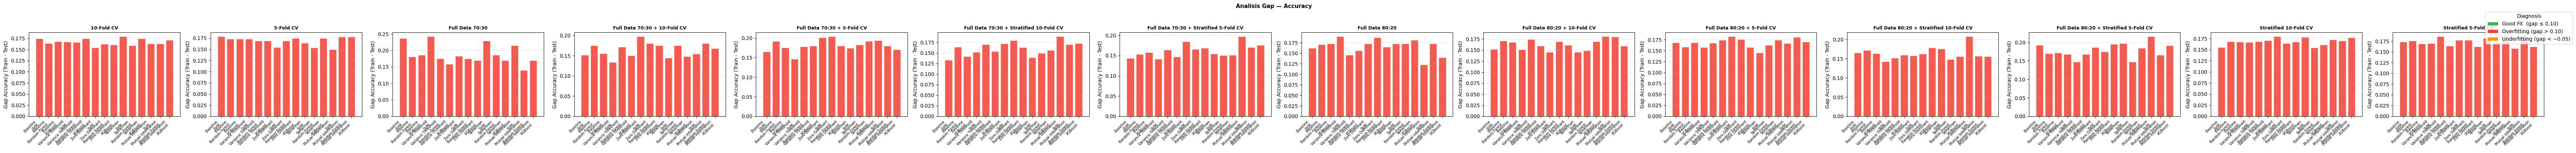

In [26]:
plot_gap_analysis(df_results, metric='Accuracy')

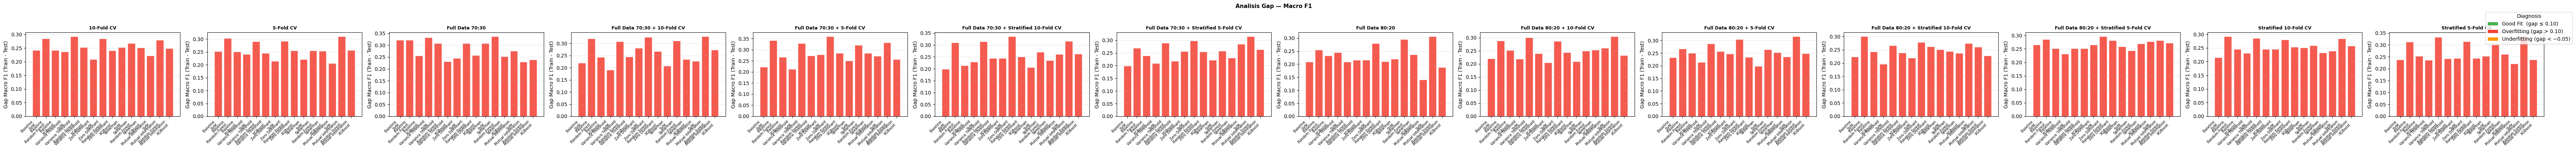

In [27]:
plot_gap_analysis(df_results, metric='Macro F1')

## 8. Performa Metrik Lengkap per Skenario

In [28]:
COLS_METRIC = ['Skenario', 'Feature Selection', 'Model'] + METRICS
for scen in df_results['Skenario'].unique():
    print(f'\n{"="*80}\n {scen}\n{"="*80}')
    sub = df_results[df_results['Skenario'] == scen]
    for model in sub['Model'].unique():
        print(f'\n  -- {model}')
        tbl = (sub[sub['Model'] == model][COLS_METRIC]
               .drop(columns=['Skenario', 'Model'])
               .set_index('Feature Selection').round(4))
        print(tbl.to_string())


 Full Data 80:20

  -- SVM
                    Accuracy  Precision  Recall  F1-Score     MCC  ROC-AUC
Feature Selection                                                         
Baseline              0.8250     0.7665  0.7833    0.7740  0.5495   0.8674
Variance Threshold    0.8083     0.7456  0.7611    0.7525  0.5064   0.8385
Zero Dominant         0.8167     0.7579  0.7889    0.7701  0.5459   0.8652
Spearman              0.8167     0.7565  0.7778    0.7656  0.5339   0.8600
Mutual Information    0.7833     0.7214  0.7556    0.7332  0.4758   0.8487

  -- Random Forest
                    Accuracy  Precision  Recall  F1-Score     MCC  ROC-AUC
Feature Selection                                                         
Baseline              0.8000     0.7365  0.6889    0.7054  0.4228   0.8830
Variance Threshold    0.8083     0.7463  0.7167    0.7287  0.4620   0.8793
Zero Dominant         0.7833     0.7087  0.6667    0.6809  0.3730   0.8726
Spearman              0.8250     0.8343  0.6722    0

## 9. Visualisasi MCC

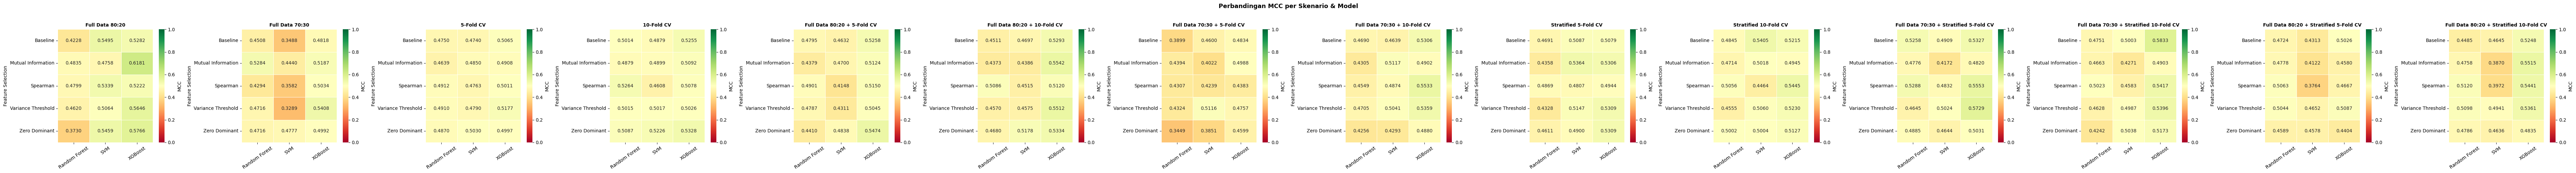

In [29]:
plot_mcc_heatmap(df_results, models)

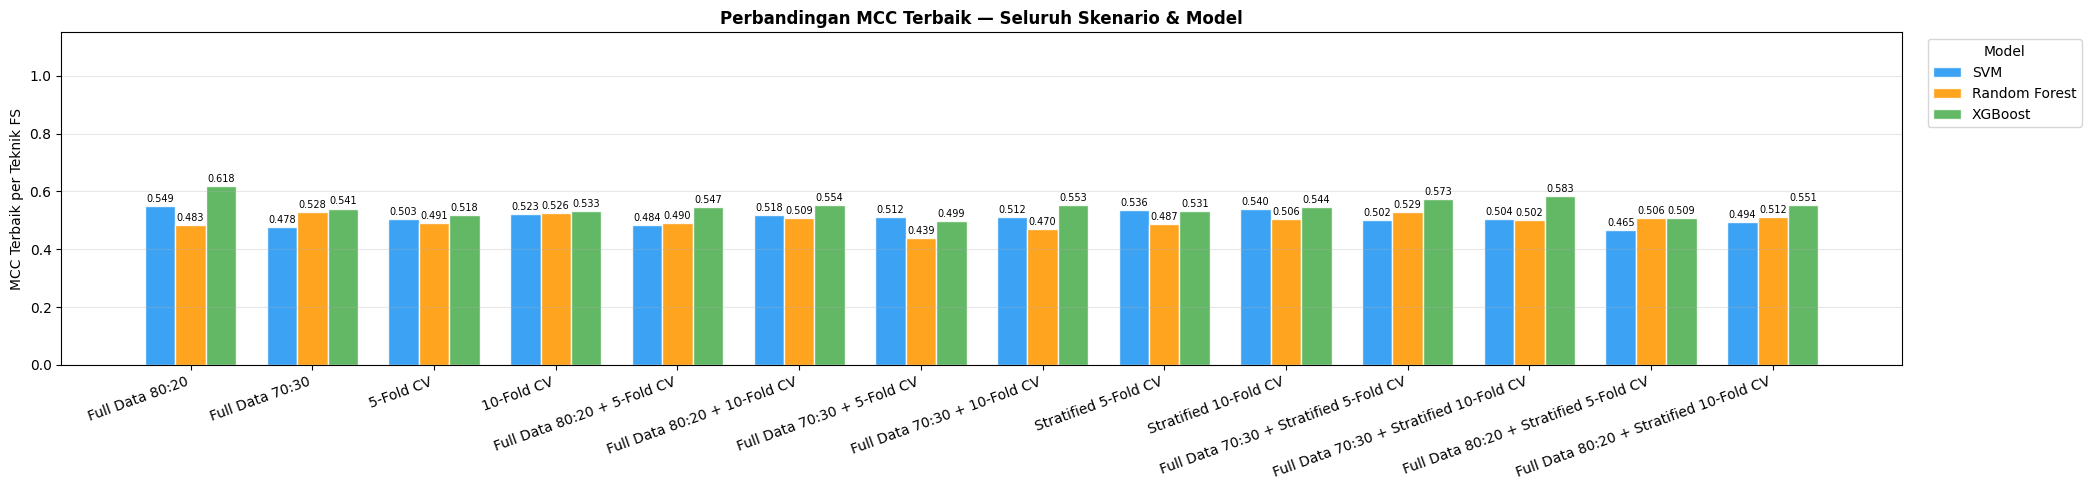

In [30]:
plot_mcc_bar(df_results, models)

## 10. Kesimpulan — Model, FS, dan Strategi Terbaik

In [31]:
best = df_results.loc[df_results['MCC'].idxmax()]
print('=' * 65)
print(f"  Skenario Terbaik  : {best['Skenario']}")
print(f"  Feature Selection : {best['Feature Selection']}")
print(f"  Model             : {best['Model']}")
print('-' * 65)
for m_name in METRICS:
    if m_name in best and pd.notna(best[m_name]):
        print(f"  {m_name:<14}: {best[m_name]:.4f}")
print('-' * 65)
print(f"  Train Accuracy : {best['Train Accuracy']:.4f} | Test Accuracy : {best['Test Accuracy']:.4f}")
print(f"  Gap Accuracy   : {best['Gap Accuracy']:.4f}")
print(f"  Train Macro F1 : {best['Train Macro F1']:.4f} | Test Macro F1 : {best['Test Macro F1']:.4f}")
print(f"  Gap Macro F1   : {best['Gap Macro F1']:.4f}")
print('=' * 65)
print('\n-> Informasi diteruskan ke 02_Main.ipynb')
print(f"  BEST_MODEL    = '{best['Model']}'")
print(f"  BEST_FS       = '{best['Feature Selection']}'")
print(f"  BEST_SCENARIO = '{best['Skenario']}'")

  Skenario Terbaik  : Full Data 80:20
  Feature Selection : Mutual Information
  Model             : XGBoost
-----------------------------------------------------------------
  Accuracy      : 0.8583
  Precision     : 0.8126
  Recall        : 0.8056
  F1-Score      : 0.8090
  MCC           : 0.6181
  ROC-AUC       : 0.8967
-----------------------------------------------------------------
  Train Accuracy : 0.9979 | Test Accuracy : 0.8583
  Gap Accuracy   : 0.1396
  Train Macro F1 : 0.9972 | Test Macro F1 : 0.8090
  Gap Macro F1   : 0.1882

-> Informasi diteruskan ke 02_Main.ipynb
  BEST_MODEL    = 'XGBoost'
  BEST_FS       = 'Mutual Information'
  BEST_SCENARIO = 'Full Data 80:20'


In [32]:
df_results.to_csv('hasil_validasi_strategi_v10.csv', index=False)
print('File tersimpan: hasil_validasi_strategi_v10.csv')

File tersimpan: hasil_validasi_strategi_v10.csv


## 11. Simpan Skenario

In [33]:
import joblib

checkpoint = {
    'rows_s1' : rows_s1,  'rows_s2' : rows_s2,
    'rows_s3' : rows_s3,  'rows_s4' : rows_s4,
    'rows_s5' : rows_s5,  'rows_s6' : rows_s6,
    'rows_s7' : rows_s7,  'rows_s8' : rows_s8,
    'rows_s9' : rows_s9,  'rows_s10': rows_s10,
    'rows_s11': rows_s11, 'rows_s12': rows_s12,
    'rows_s13': rows_s13, 'rows_s14': rows_s14,
}
joblib.dump(checkpoint, 'all_rows_checkpoint.pkl')
print('Checkpoint tersimpan!')

Checkpoint tersimpan!
